## Milestone 1: represent and check the system.

this first snippet of code aim to run a tests for small configurations. The result is compared against the calculation done by hand. We descided to run total of 4 tests.

**Tests**
- 5x5 lattice initialisation testing: create a 5x5 random and ordered (all 1 or -1) lattice (matrix) and print it.
- 3x3 lattice testing: compared the hand calculated E (total energy), e (energy per spin), M (total magnetism), m (magnetization per spin) for [[ 1,  1, -1], [ 1, -1, -1], [-1, -1,  1]] lattice.
- 4x4 ordered lattice testing: simmilar to previous test, compared the hand calculated E, e, M, m against computed ones for 4x4 ordered lattice ( all up or down)
- energy change calculation: 

**Functions**

In this code we mainly used 5 main supporting function we created in supporting_function.py here is the brief break down of what each function does.

| Function    | What it does |
| -------- | ------- |
| make_lattice (L, mode = "random")| create a LxL matrix, you can set the mode to either "random", "up", or "down". "random" generates random lattice and "up" and "down" you can generate ordered lattice. |
| calc_E_e(lattice, J=1.0, h=0.0) | calculates the E and e of your LxL lattice. |
| calc_M_m(lattice) | calculates the M and m of your LxL lattice. |
| calc_flip_E (lattice, i, j, J=1.0, h=0.0) | apply periodic boundary and calculates the neighbor sum and outputs the Energy changed from flipping. |

*all details to function are in supporting_function.py

**Example Calculation**

Example calculation for 2x2 lattice

$$
lattice = \begin{bmatrix} +1 & +1 & -1 \\ +1 & -1 & -1 \\ -1 & -1 & +1 \end{bmatrix}
$$

 1. total energy (E) and energy per spin (e)
to calculate the total energy we need to use this equation

$$
E = -J \sum_{\langle i,j\rangle} s_i s_j - h \sum_{i=1}^{N} s_i
$$

but since h is 0, we simply need to calculate the products of all nearest-neighbour spin pairs, $\sum_{\langle i,j\rangle} s_i s_j$, and multiply it by $-J$. With periodic boundary conditions, a 3x3 lattice has $2N = 18$ bonds, each counted once. We count the right bond and the down bond of every site, including the bonds that wrap around the edges.

| Row |	Bonds |	Products | Sum |
|--------|--------|--------|--------|
| 0 | (+1)(+1), (+1)(−1), (−1)(+1) | +1, −1, −1 | −1 |
| 1 | (+1)(−1), (−1)(−1), (−1)(+1) | −1, +1, −1 | −1 |
| 2	| (−1)(−1), (−1)(+1), (+1)(−1) | +1, −1, −1 | −1 |



In [1]:
import supporting_function as sf
import numpy as np

#------- testing 5x5 lattice initialization -------

rand_lattice = sf.make_lattice(5, mode = "random")
print("------- random lattice -------")
print(f"Random lattice:\n{rand_lattice}\n")

ordered_up_lattice = sf.make_lattice(5, mode = "up")
print("------- ordered up lattice -------")
print(f"Ordered up lattice:\n{ordered_up_lattice}\n")

#------- 3x3 lattice testing -------

test_lattice = np.array([[ 1,  1, -1], [ 1, -1, -1], [-1, -1,  1]])

E, e = sf.calc_E_e(test_lattice)
M, m = sf.calc_M_m(test_lattice)

#calculation is on note.md
print("------- 3x3 lattice test-------")
print(f"Total Energy: {E} (expected: 6.0)")
print(f"Energy per spin: {e} (expected: 0.6667)")
print(f"Total Magnetism: {M} (expected: -1.0)")
print(f"Magnetization per spin: {m} (expected: -0.1111)\n")

#------- 4x4 ordered lattice test -------

up_lattice  = sf.make_lattice(4, mode = "up")
down_lattice = sf.make_lattice(4, mode = "down")

E_up, e_up = sf.calc_E_e(up_lattice)
E_down, e_down = sf.calc_E_e(down_lattice)

M_up, m_up = sf.calc_M_m(up_lattice)
M_down, m_down = sf.calc_M_m(down_lattice)

print("------- up lattice test-------")
print(f"Total Energy: {E_up} (expected: -32.0), Energy per spin: {e_up} (expected: -2.0) ")
print(f"Total Magnetism: {M_up} (expected: 16.0), Magnetization per spin: {m_up} (expected: 1.0)\n")

print("------- down lattice test-------")
print(f"Total Energy: {E_down} (expected: -32.0), Energy per spin: {e_down} (expected: -2.0) ")
print(f"Total Magnetism: {M_down} (expected: -16.0), Magnetization per spin: {m_down} (expected: -1.0)\n")

#------- testing if the energy change calculation is correct ------

rand_lattice = sf.make_lattice(5, mode = "random")
E_initial, e_initial = sf.calc_E_e(rand_lattice)
Matched = True

test_position = [(0,0),(4,4),(0,4),(4,0),(0,2),(4,2),(2,0),(2,4),(2,2)]

print("------- testing energy change calculation after flipping spins -------")
for r, c in test_position:
    flip_E = sf.calc_flip_E(rand_lattice, r, c)

    flipped_grid = rand_lattice.copy()
    flipped_grid[r, c] *= -1
    E_flipped, e_flipped = sf.calc_E_e(flipped_grid)
    print (f"Flipping spin at position ({r}, {c}): calculated energy change: {flip_E}, expected energy change: {E_flipped - E_initial}")
    if flip_E != (E_flipped - E_initial):
        Matched = False
        
print("\n")
if Matched:
    print("All energy change calculations are correct!")
else:
    print("Some energy change calculations are incorrect!")

------- random lattice -------
Random lattice:
[[ 1 -1 -1  1 -1]
 [-1 -1 -1  1 -1]
 [-1 -1  1  1  1]
 [-1  1 -1  1 -1]
 [-1  1  1 -1 -1]]

------- ordered up lattice -------
Ordered up lattice:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

------- 3x3 lattice test-------
Total Energy: 6.0 (expected: 6.0)
Energy per spin: 0.6666666666666666 (expected: 0.6667)
Total Magnetism: -1 (expected: -1.0)
Magnetization per spin: -0.1111111111111111 (expected: -0.1111)

------- up lattice test-------
Total Energy: -32.0 (expected: -32.0), Energy per spin: -2.0 (expected: -2.0) 
Total Magnetism: 16 (expected: 16.0), Magnetization per spin: 1.0 (expected: 1.0)

------- down lattice test-------
Total Energy: -32.0 (expected: -32.0), Energy per spin: -2.0 (expected: -2.0) 
Total Magnetism: -16 (expected: -16.0), Magnetization per spin: -1.0 (expected: -1.0)

------- testing energy change calculation after flipping spins -------
Flipping spin at position (0, 0): calculated energy c

## Milestone 2: generate and analyse trajectories.

**Test 1**

This first test run the whole 5,000-sweep at T = 1 K and output it's E,e, M, m calculation and graph plotting.


**Functions**
| Function    | What it does |
| -------- | ------- |
| def run_sweep(s, T, num_sweeps, J=1.0, h=0.0, rng = none) | run montecarlo testing num_sweep times |


------- Initial random lattice -------



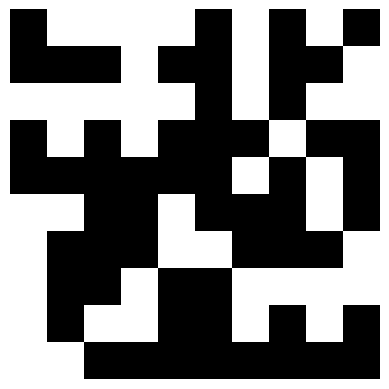

+1/up = black, -1/down = white

------- Final lattice after Monte Carlo sweep (1K) -------



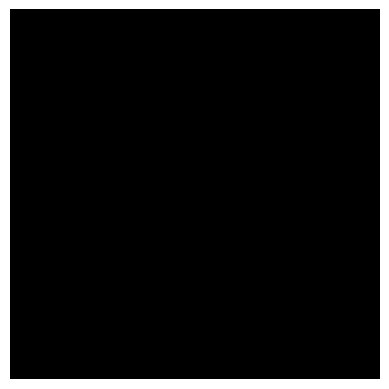

+1/up = black, -1/down = white

------- Final Energy and Magnetism after Monte Carlo sweep (1K) -------

Total Energy: -200
Energy per spin: -2.0
Total Magnetism: -100
Magnetization per spin: -1.0

------- Plotting Magnetization vs Sweeps -------


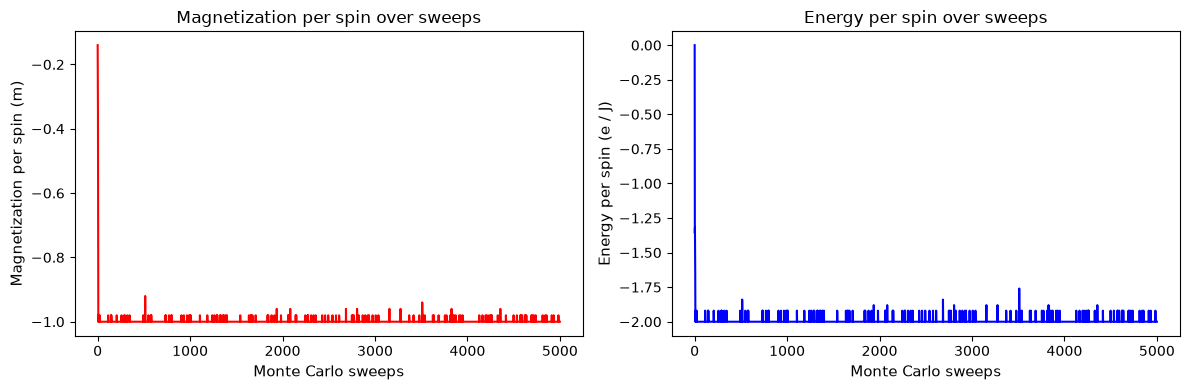

In [16]:
import numpy as np 
import supporting_function as sf
import matplotlib.pyplot as plt

#-----set up-----
L = 10 # lattice size
SEED = 77
rng = np.random.default_rng(SEED)

h = 0 #external magnetic field
J = 1 #interaction energy
k_1 = 1 #Boltzmann constant and it said that J*k_B = 1
T = 1 #temperature

# ----- 1K testing with random initial configuration ------
s = sf.make_lattice(L, mode="random", rng=rng) # let s = the array of spins, with each spin being either +1 or -1
#Monte Carlo Sweep

print("------- Initial random lattice -------\n")

#diagram to show up and down using black and white boxes (+1/up = black, -1/down = white)
plt.imshow(s, cmap="gray", vmin=-1, vmax=1)
plt.axis("off")
plt.show()

print("+1/up = black, -1/down = white\n")

s, m_list, e_list = sf.run_sweep(s, T, 5000, rng=rng)

print("------- Final lattice after Monte Carlo sweep (1K) -------\n")

plt.imshow(s, cmap="gray", vmin=-1, vmax=1)
plt.axis("off")
plt.show()

print("+1/up = black, -1/down = white\n")

E, e = sf.calc_E_e(s, J, h)
M, m = sf.calc_M_m(s)

print("------- Final Energy and Magnetism after Monte Carlo sweep (1K) -------\n")
print(f"Total Energy: {E}")
print(f"Energy per spin: {e}")
print(f"Total Magnetism: {M}")
print(f"Magnetization per spin: {m}\n")

print("------- Plotting Magnetization vs Sweeps -------")
t = np.arange(len(m_list))
plt.figure(figsize = (12,4)) 
plt.subplot(1,2,1)
plt.plot(t, m_list, color="red")

plt.title("Magnetization per spin over sweeps")
plt.xlabel("Monte Carlo sweeps", fontsize=11)
plt.ylabel('Magnetization per spin (m)', fontsize=11)

plt.subplot(1,2,2)
plt.plot(t, e_list, color="blue")

plt.title("Energy per spin over sweeps")
plt.xlabel("Monte Carlo sweeps", fontsize=11)
plt.ylabel("Energy per spin (e / J)", fontsize=11)

plt.tight_layout()
plt.show()


**Test 2**

This code updates and produce trajectories of e(t) and m(t) from different initial configurations, together with snapshots of the states reached after long runs.

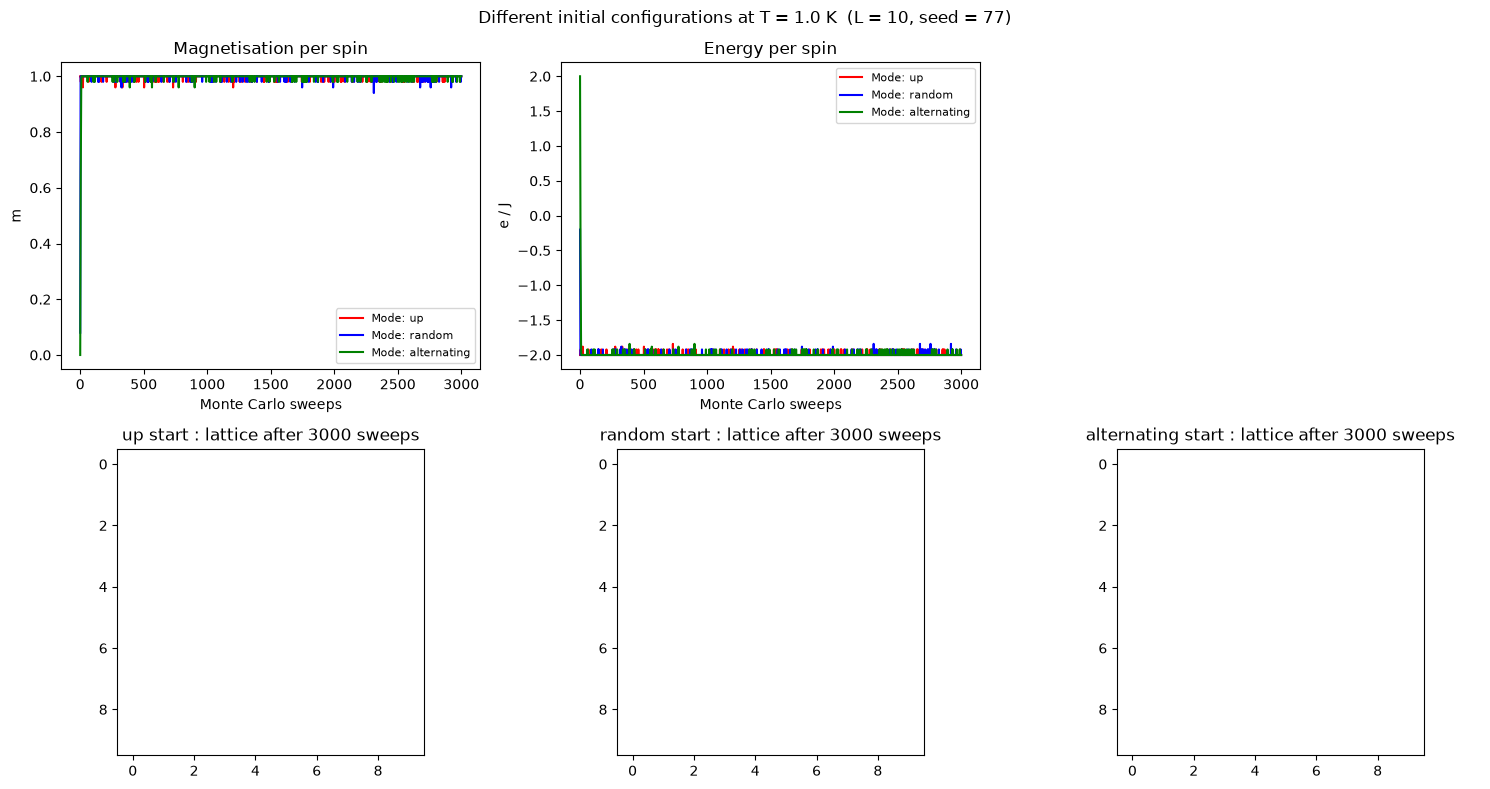

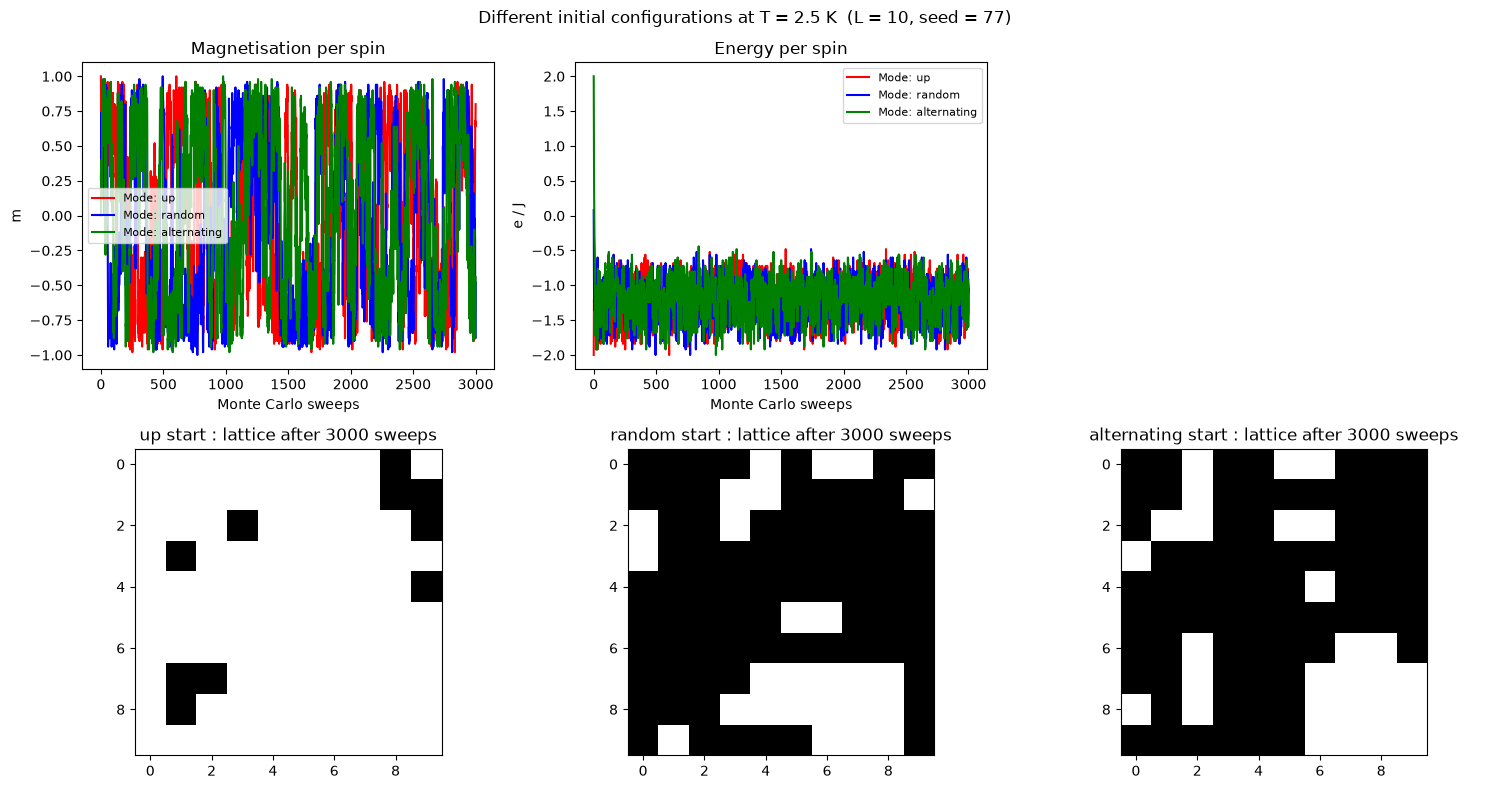

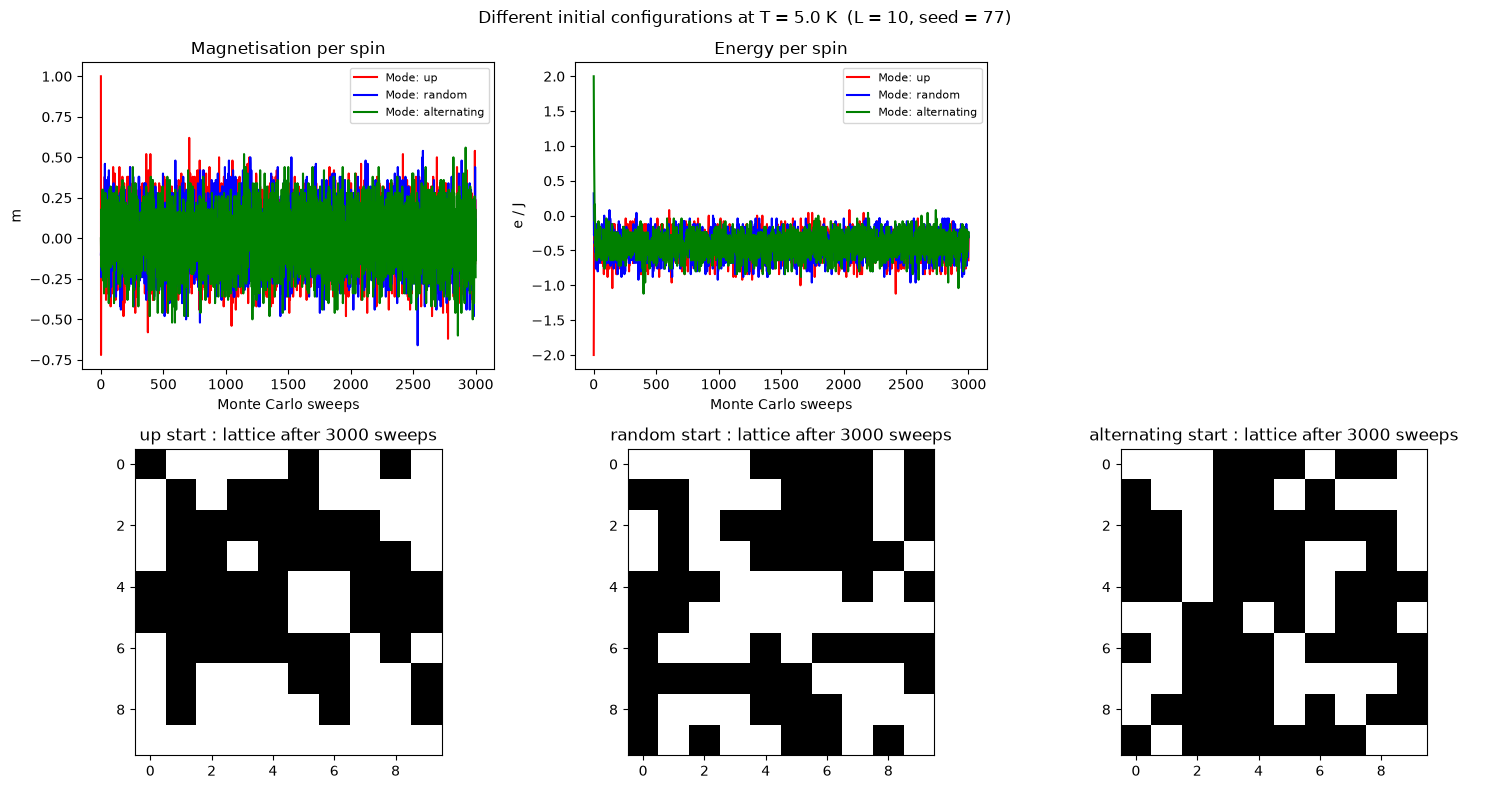

In [ ]:
mode = ["up", "random", "alternating"]
colour = ["red", "blue", "green"]
T2 = [1.0, 2.5, 5.0]
n_sweeps=3000

def different_initial_configurations(L, mode, T2, n_sweeps, J, h, rng):
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    ax[0, 2].axis("off")

    for k, mode in enumerate(mode):
        s = sf.make_lattice(L, mode, rng)
        s, m_t, e_t = sf.run_sweep(s, T2, n_sweeps, J, h, rng=rng)

        ax[0, 0].plot(m_t, color=colour[k], label=f"Mode: {mode}")
        ax[0, 1].plot(e_t, color=colour[k], label=f"Mode: {mode}")

        ax[1, k].imshow(s, cmap="gray", vmin=-1, vmax=1)
        ax[1, k].set_title(f"{mode} start : lattice after {n_sweeps} sweeps")

    ax[0, 0].set_title("Magnetisation per spin");         
    ax[0, 0].set_ylabel("m")
    ax[0, 1].set_title("Energy per spin");                
    ax[0, 1].set_ylabel("e / J")

    ax[0, 0].set_xlabel("Monte Carlo sweeps")
    ax[0, 0].legend(loc="best", fontsize=8)
    ax[0, 1].set_xlabel("Monte Carlo sweeps")
    ax[0, 1].legend(loc="best", fontsize=8)

    fig.suptitle(f"Different initial configurations at T = {T2} K  (L = {L}, seed = {SEED})")
    plt.tight_layout()
    plt.show()

for T_val in T2:
    different_initial_configurations(L, mode, T_val, n_sweeps, J, h, rng)